## __NB04 Visualization Demo__

*Author: Shilpa Kibe. Licensed under CC BY-NC 4.0.*

**Continuing from NB03**

NB03 turned approved course matches into personalised learning paths.

- L&D reviewed 19 uncertain matches: 12 approved, 4 switched, 2 replaced, 1 content gap (KSB018)
- 29 of 30 KSBs now have one approved course
- `learning_path_recommendations.csv`: 687 path steps for 55 employees (5 to 21 steps each)
- KSB018 appears as a "coming soon" step for 19 employees
- An access demo showed each employee sees only their own path
- `kpi_impact_rollup.csv`: K2.2 and K2.1, actual vs projected vs target

**NB03 produced the data. NB04 presents it.**

### __Overview__

NB04 turns the Phase 1 outputs into figures for stakeholders and the README.

**What this notebook shows**
- Where L&D judgment sits in the pipeline (curation flow)
- How long paths are spread over yearly cycles
- Two contrasting paths: Instructional Design Lead vs Solution Architect
- KPI impact for leaders, aggregate only

**Phasing rules (settings at the top)**
- 40 learning hours per year, minus 5 hours for mandatory, compliance and QMS training
- 35 hours available per cycle for the path
- Max 6 KSB gaps per cycle (the K2.2 target)
- A cycle ends when either cap is reached

**Ground rules**
- Read only. No CSV is changed. Phasing is computed for display, not saved
- Employee IDs only in figures. No names
- Groups under 5 people are never shown in summaries (minimum group size)
- All figures saved as PNG to `reports/figures/`
- **Note:**
  - Path charts use the same privacy check as NB03: an employee can only see their own path
  - *Under the hood:* `plot_path()` calls `can_view(logged_in_id, requested_id)`, the same rule as NB03 `view_my_path`, and draws nothing if the IDs differ

**Steps**
- Step 4.1 Setup and load data (incl. 4.1.5 minimum group size)
- Step 4.2 Curation flow
- Step 4.3 Path phasing over yearly cycles
- Step 4.4 Two contrasting paths
- Step 4.5 KPI dashboard
- Step 4.6 Figure index

### __Step 4.1: Setup and load data__

- Mount Drive safely and set folder paths.
- Set the phasing rules and chart style in one place, so they are easy to change.
- Load the tables NB04 needs. No names are loaded: figures use employee IDs only (GDPR-aligned data minimisation).
  - *Under the hood:* `employees_pii.csv` is deliberately not read in this notebook
- Create `reports/figures/` if it does not exist.

In [1]:
# Step 4.1: Mount Drive (idempotent, ADR-0033), settings, load tables
# Reads: data/raw (courses, ksbs, competencies, employees, roles)
#        data/processed (learning_path_recommendations, employee_ksb_gaps, course_ksb_mapping)
#        outputs (curation_review_sheet_completed, kpi_impact_rollup)

import os
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

if not os.path.ismount('/content/drive'):
    drive.mount('/content/drive')
else:
    print("Drive already mounted, skipping remount, nothing deleted.")

ROOT_DIR = '/content/drive/MyDrive/Portfolio/LuminaLearningGroup'
RAW_DIR = os.path.join(ROOT_DIR, 'data', 'raw')
PROCESSED_DIR = os.path.join(ROOT_DIR, 'data', 'processed')
OUTPUT_DIR = os.path.join(ROOT_DIR, 'outputs')
FIGURES_DIR = os.path.join(ROOT_DIR, 'reports', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)
RANDOM_STATE = 42

# Step 4.1.1: Phasing rules (agreed in NB04 open items)
ANNUAL_LEARNING_HOURS = 40      # learning hours per employee per year
MANDATORY_HOURS = 5             # compliance (max 3 modules, 45 to 60 min each) plus QMS
PATH_HOURS_PER_CYCLE = ANNUAL_LEARNING_HOURS - MANDATORY_HOURS   # 35 hours for the path
KSB_PER_CYCLE = 6               # K2.2 target: 6 KSBs per year

# Step 4.1.2: Chart style (one colour-blind-safe palette for all figures)
FIG_DPI = 150
COLORS = {
    'knowledge': '#0072B2',     # blue
    'skill': '#E69F00',         # orange
    'behavior': '#009E73',      # green
    'content_gap': '#999999',   # grey, "coming soon"
    'target': '#D55E00',        # vermillion, target lines
}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

# Step 4.1.3: Read CSVs (no PII loaded in NB04)
courses = pd.read_csv(os.path.join(RAW_DIR, 'courses.csv'))
ksbs = pd.read_csv(os.path.join(RAW_DIR, 'ksbs.csv'))
competencies = pd.read_csv(os.path.join(RAW_DIR, 'competencies.csv'))
employees = pd.read_csv(os.path.join(RAW_DIR, 'employees.csv'))
roles = pd.read_csv(os.path.join(RAW_DIR, 'roles.csv'))
learning_path_recommendations = pd.read_csv(os.path.join(PROCESSED_DIR, 'learning_path_recommendations.csv'))
employee_ksb_gaps = pd.read_csv(os.path.join(PROCESSED_DIR, 'employee_ksb_gaps.csv'))
course_ksb_mapping = pd.read_csv(os.path.join(PROCESSED_DIR, 'course_ksb_mapping.csv'))
curation_completed = pd.read_csv(os.path.join(OUTPUT_DIR, 'curation_review_sheet_completed.csv'), encoding='utf-8-sig')
kpi_impact_rollup = pd.read_csv(os.path.join(OUTPUT_DIR, 'kpi_impact_rollup.csv'))

print("Step 4.1 executed: tables loaded, figures folder ready")
print(f"Phasing: {PATH_HOURS_PER_CYCLE} path hours per cycle ({ANNUAL_LEARNING_HOURS} minus {MANDATORY_HOURS} mandatory), "
      f"max {KSB_PER_CYCLE} KSBs per cycle")
print()
for name, df in [('courses.csv', courses), ('ksbs.csv', ksbs), ('competencies.csv', competencies),
                 ('employees.csv', employees), ('roles.csv', roles),
                 ('learning_path_recommendations.csv', learning_path_recommendations),
                 ('employee_ksb_gaps.csv', employee_ksb_gaps), ('course_ksb_mapping.csv', course_ksb_mapping),
                 ('curation_review_sheet_completed.csv', curation_completed),
                 ('kpi_impact_rollup.csv', kpi_impact_rollup)]:
    print(f"{name}: {len(df)} rows, {len(df.columns)} columns")
print()

# Step 4.1.4: Quick check: employees with a path, by role
path_emps = (learning_path_recommendations[['employee_id']].drop_duplicates()
             .merge(employees[['employee_id', 'role_id']], on='employee_id', how='left')
             .merge(roles[['role_id', 'role_name']], on='role_id', how='left'))
print("Employees with a path, by role:")
print(path_emps['role_name'].value_counts())

Mounted at /content/drive
Step 4.1 executed: tables loaded, figures folder ready
Phasing: 35 path hours per cycle (40 minus 5 mandatory), max 6 KSBs per cycle

courses.csv: 154 rows, 16 columns
ksbs.csv: 30 rows, 4 columns
competencies.csv: 10 rows, 2 columns
employees.csv: 430 rows, 6 columns
roles.csv: 4 rows, 4 columns
learning_path_recommendations.csv: 687 rows, 7 columns
employee_ksb_gaps.csv: 1650 rows, 6 columns
course_ksb_mapping.csv: 9240 rows, 9 columns
curation_review_sheet_completed.csv: 19 rows, 27 columns
kpi_impact_rollup.csv: 6 rows, 4 columns

Employees with a path, by role:
role_name
Instructional Design Lead                    50
Capability Development/Solution Architect     5
Name: count, dtype: int64


### __Step 4.1 Notes/Insights__

- All 10 tables loaded from Drive. No names were loaded.
- Paths exist for all 55 focus-role employees: 50 Instructional Design Leads and 5 Solution Architects.
- 687 path rows match NB03, so NB04 starts from the same data.
- Phasing settings are fixed at the top: 35 path hours and max 6 KSBs per cycle.
- `reports/figures/` is ready for the README images.

### __Step 4.1.5: Minimum group size (privacy for small groups)__

- Totals can still reveal a person if the group is tiny. For example, an average for 1 or 2 people is almost their own score.
- So any group smaller than `MIN_GROUP_SIZE` (5) is shown as "Suppressed (<5)", never with its values.
- One setting, one function, used before every summary table or chart is shown or saved.
  - *Under the hood:* `suppress_small_groups(df, group_col, count_col)` hides all values for groups under the limit
- The data is not changed. Solution Architects stay at 5, the real org-chart number. The fix is in reporting, as in real HR analytics.
- Not applied to Step 4.2 (it counts courses, not people) or Step 4.4 (individual paths, already protected by the own-path-only check).

In [2]:
# Step 4.1.5: Minimum group size setting and small-group suppression function
MIN_GROUP_SIZE = 5   # groups smaller than this are never shown with their values

def suppress_small_groups(df, group_col, count_col, min_size=None):
    """Hide every value for groups with fewer than min_size people.
    Returns (safe_table, number_of_groups_suppressed)."""
    min_size = MIN_GROUP_SIZE if min_size is None else min_size
    group_cols = [group_col] if isinstance(group_col, str) else list(group_col)
    out = df.copy()
    small = out[count_col] < min_size
    value_cols = [c for c in out.columns if c not in group_cols]
    out[value_cols] = out[value_cols].astype(object)
    out.loc[small, value_cols] = f"Suppressed (<{min_size})"
    return out, int(small.sum())

# Step 4.1.5: Quick self-test on a toy table
_test = pd.DataFrame({'group': ['A', 'B'], 'n': [12, 3], 'avg_hours': [6.1, 9.4]})
_safe, _n_hidden = suppress_small_groups(_test, 'group', 'n')
assert _n_hidden == 1 and _safe.loc[1, 'avg_hours'] == f"Suppressed (<{MIN_GROUP_SIZE})"
print(f"Step 4.1.5 executed: MIN_GROUP_SIZE = {MIN_GROUP_SIZE}; suppression function ready (self-test passed)")

Step 4.1.5 executed: MIN_GROUP_SIZE = 5; suppression function ready (self-test passed)


### __Step 4.1.5 Notes/Insights__

- The minimum group size is set once, at 5 people.
- The check passed its own test: a group of 3 was hidden, and a group of 12 was shown.
- From here on, every summary of people goes through this check before it is shown or saved.

### __Step 4.2: Curation flow (where L&D judgment sits)__

- Shows how 30 AI course matches became approved learning content.
- Blue boxes: the algorithm's work. Orange boxes: the L&D reviewer's decisions.
- Counts are read from the data, not typed in.
  - *Under the hood:* counts come from `course_ksb_mapping.csv` (TF-IDF recommended rows and `curation_status`) and `curation_review_sheet_completed.csv` (decisions)
- Saved as `fig_4_2_curation_flow.png`.

Step 4.2.1 executed: curation flow counted
30 matches -> 11 auto-approved, 19 to L&D review
Review: 12 approved, 4 switched, 2 replaced, 1 content gap ['KSB018']
End: 29 KSBs with one approved course, 1 content gap


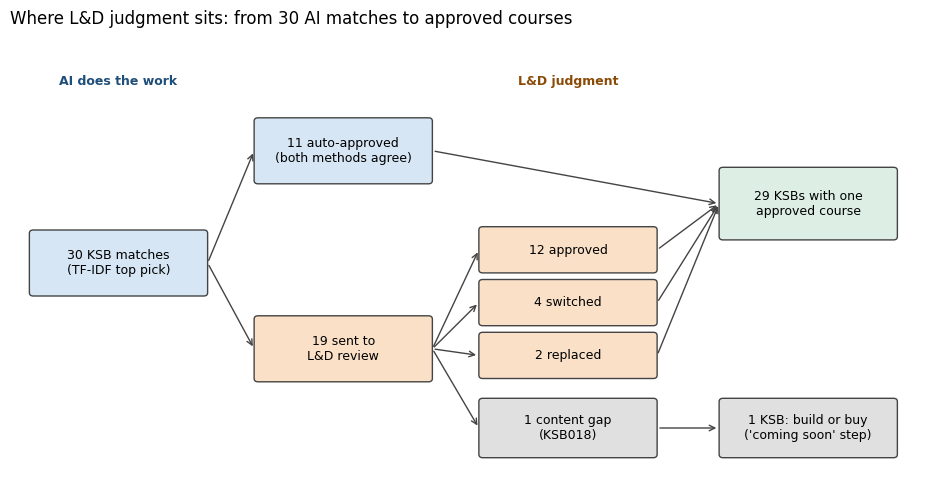

Step 4.2.2 executed: fig_4_2_curation_flow.png saved to reports/figures


In [3]:
# Step 4.2: Curation flow chart
# Reads (in memory): course_ksb_mapping, curation_completed, ksbs
# Saves: reports/figures/fig_4_2_curation_flow.png

from matplotlib.patches import FancyBboxPatch

# Step 4.2.1: Count the flow from the data
is_tfidf = course_ksb_mapping['match_method'] == 'tfidf'
n_total = course_ksb_mapping[is_tfidf & (course_ksb_mapping['is_recommended'] == True)]['ksb_id'].nunique()
n_review = curation_completed['ksb_id'].nunique()
n_auto = n_total - n_review

decision = curation_completed['decision'].str.strip().str.split().str[0].str.lower()
replacement = curation_completed['replacement_course_id'].fillna('').astype(str).str.strip()
n_approve = (decision == 'approve').sum()
n_switch = (decision == 'switch').sum()
n_replace = ((decision == 'reject') & (replacement != '')).sum()
n_gap = ((decision == 'reject') & (replacement == '')).sum()

eligible = course_ksb_mapping[is_tfidf & course_ksb_mapping['curation_status'].isin(['ld_approved', 'ld_modified'])]
n_with_course = eligible['ksb_id'].nunique()
gap_ksbs = sorted(set(ksbs['ksb_id']) - set(eligible['ksb_id']))

assert n_approve + n_switch + n_replace + n_gap == n_review, "Review decisions do not add up"
assert n_with_course + len(gap_ksbs) == n_total, "Final KSB counts do not add up"

print("Step 4.2.1 executed: curation flow counted")
print(f"{n_total} matches -> {n_auto} auto-approved, {n_review} to L&D review")
print(f"Review: {n_approve} approved, {n_switch} switched, {n_replace} replaced, {n_gap} content gap {gap_ksbs}")
print(f"End: {n_with_course} KSBs with one approved course, {len(gap_ksbs)} content gap")

# Step 4.2.2: Draw the box-flow chart
FILL = {'algo': '#D6E6F4', 'human': '#F9E0C7', 'result': '#DDEFE5', 'gap': '#E0E0E0'}
EDGE = '#444444'

fig, ax = plt.subplots(figsize=(12, 6))
ax.set_xlim(0, 12)
ax.set_ylim(0, 7)
ax.axis('off')

def box(x, y, text, kind, w=2.2, h=0.9):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle='round,pad=0.05',
                                fc=FILL[kind], ec=EDGE, lw=1))
    ax.text(x, y, text, ha='center', va='center', fontsize=9)
    return (x, y, w, h)

def arrow(a, b):
    ax.annotate('', xy=(b[0] - b[2]/2 - 0.05, b[1]), xytext=(a[0] + a[2]/2 + 0.05, a[1]),
                arrowprops=dict(arrowstyle='->', color=EDGE, lw=1))

start = box(1.4, 3.5, f"{n_total} KSB matches\n(TF-IDF top pick)", 'algo')
auto = box(4.3, 5.2, f"{n_auto} auto-approved\n(both methods agree)", 'algo')
review = box(4.3, 2.2, f"{n_review} sent to\nL&D review", 'human')
outcomes = [box(7.2, 3.7, f"{n_approve} approved", 'human', h=0.6),
            box(7.2, 2.9, f"{n_switch} switched", 'human', h=0.6),
            box(7.2, 2.1, f"{n_replace} replaced", 'human', h=0.6),
            box(7.2, 1.0, f"{n_gap} content gap\n({', '.join(gap_ksbs)})", 'gap', h=0.8)]
end_ok = box(10.3, 4.4, f"{n_with_course} KSBs with one\napproved course", 'result', h=1.0)
end_gap = box(10.3, 1.0, f"{len(gap_ksbs)} KSB: build or buy\n('coming soon' step)", 'gap', h=0.8)

arrow(start, auto)
arrow(start, review)
for o in outcomes:
    arrow(review, o)
arrow(auto, end_ok)
for o in outcomes[:3]:
    arrow(o, end_ok)
arrow(outcomes[3], end_gap)

ax.text(1.4, 6.2, 'AI does the work', ha='center', fontsize=9, color='#1F4E79', fontweight='bold')
ax.text(7.2, 6.2, 'L&D judgment', ha='center', fontsize=9, color='#8A4B08', fontweight='bold')
ax.set_title('Where L&D judgment sits: from 30 AI matches to approved courses', loc='left', fontsize=12)

fig_path = os.path.join(FIGURES_DIR, 'fig_4_2_curation_flow.png')
fig.savefig(fig_path, dpi=FIG_DPI, bbox_inches='tight')
plt.show()
print(f"Step 4.2.2 executed: fig_4_2_curation_flow.png saved to reports/figures")

### __Step 4.2 Notes/Insights__

- The algorithm handled 11 of 30 matches on its own, where both methods agreed.
- 19 needed a human decision. The reviewer kept 12 and changed 6.
- One skill (KSB018) had no suitable course. It is logged as "build or buy", not hidden.
- End result: 29 of 30 skills have one approved course.
- This is "AI proposes, L&D decides" in one picture.
- We use matplotlib (instead of Sankey) here so all README figures share one static style.
  - A Sankey diagram (Plotly) would show the flow more visually.

### __Step 4.3: Path phasing over cycles__

- Paths are too long for one year (K2.2 projection is about twice the target), so each path is split into annual cycles.
- Steps stay in path order. A new cycle starts when the next step would break either cap:
  - 35 hours of course time (40 learning hours minus 5 mandatory)
  - 6 KSB gaps (the K2.2 target)
- A shared course counts as 2 KSBs, since it closes 2 gaps.
- "Coming soon" steps have no course yet, so they are marked pending, not placed in a cycle.
- Display only: the cycle is not saved to any CSV.
  - *Under the hood:* the result stays in memory as `phased`, and Step 4.4 reuses it for the cycle divider

In [4]:
# Step 4.3: Path phasing over cycles (display only, nothing saved)
# Reads (in memory): learning_path_recommendations, courses
# Keeps in memory: phased (one row per path step, with its cycle)

# Step 4.3.1: Build one row per path step (a shared course is one step covering 2 KSBs)
steps = (learning_path_recommendations
         .groupby(['employee_id', 'sequence_order'])
         .agg(course_id=('course_id', 'first'), n_ksbs=('gap_id', 'size'))
         .reset_index()
         .merge(courses[['course_id', 'duration_minutes']], on='course_id', how='left'))
steps['is_content_gap'] = steps['course_id'].isna()
steps = steps.sort_values(['employee_id', 'sequence_order']).reset_index(drop=True)

print("Step 4.3.1 executed: path steps built")
print(f"Steps: {len(steps)} for {steps['employee_id'].nunique()} employees "
      f"({steps['is_content_gap'].sum()} 'coming soon' steps)")
print()

# Step 4.3.2: Assign each step to a cycle; a new cycle starts when the next step breaks either cap
def assign_cycles(emp_steps):
    cycle, hours, ksb_count = 1, 0.0, 0
    cycles, reasons = [], []
    for r in emp_steps.itertuples():
        if r.is_content_gap:                       # no course yet, so no cycle
            cycles.append(pd.NA)
            reasons.append('pending content')
            continue
        step_hours = r.duration_minutes / 60
        reason = ''
        if hours + step_hours > PATH_HOURS_PER_CYCLE:
            reason = 'hours cap'
        elif ksb_count + r.n_ksbs > KSB_PER_CYCLE:
            reason = 'KSB cap'
        if reason:                                 # start the next cycle
            cycle, hours, ksb_count = cycle + 1, 0.0, 0
        hours += step_hours
        ksb_count += r.n_ksbs
        cycles.append(cycle)
        reasons.append(reason)
    emp_steps = emp_steps.copy()
    emp_steps['cycle'] = pd.array(cycles, dtype='Int64')
    emp_steps['new_cycle_reason'] = reasons
    return emp_steps

phased = pd.concat([assign_cycles(g) for _, g in steps.groupby('employee_id')], ignore_index=True)

print("Step 4.3.2 executed: cycles assigned (in memory only)")
print("Why a new cycle started:")
print(phased.loc[phased['new_cycle_reason'].isin(['hours cap', 'KSB cap']), 'new_cycle_reason'].value_counts())
print()

# Step 4.3.3: Aggregate view (counts only)
cycles_needed = phased.groupby('employee_id')['cycle'].max()
course_hours = phased.groupby('employee_id')['duration_minutes'].sum() / 60
hours_per_cycle = phased.dropna(subset=['cycle']).groupby(['employee_id', 'cycle'])['duration_minutes'].sum() / 60

print("Step 4.3.3 executed: phasing summary")
# print("Employees by number of cycles needed:") (commented on 14 Oct 2026)
# print(cycles_needed.value_counts().sort_index().rename_axis('cycles').to_string()) (commented on 14 Oct 2026)
# print() (commented on 14 Oct 2026)
print(f"Course hours per path (min / mean / max): "
      f"{course_hours.min():.1f} / {course_hours.mean():.1f} / {course_hours.max():.1f}")
print(f"Course hours per cycle (min / mean / max): "
      f"{hours_per_cycle.min():.1f} / {hours_per_cycle.mean():.1f} / {hours_per_cycle.max():.1f}")

Step 4.3.1 executed: path steps built
Steps: 638 for 55 employees (19 'coming soon' steps)

Step 4.3.2 executed: cycles assigned (in memory only)
Why a new cycle started:
new_cycle_reason
KSB cap    73
Name: count, dtype: int64

Step 4.3.3 executed: phasing summary
Course hours per path (min / mean / max): 0.9 / 6.6 / 12.2
Course hours per cycle (min / mean / max): 0.2 / 2.8 / 5.9


### __Step 4.3 Notes/Insights__

- Only 8 of 55 employees can finish their path in one year. 22 need 2 years, and 25 need 3 or more.
- The 6-KSB cap set every cycle break (73 times). The 35-hour cap was never reached.
- Course time is small: 6.6 hours per path on average, and at most 5.9 hours in any one cycle.
- So time is not the limit. How much change a person can absorb in a year is.
- 19 "coming soon" steps are marked pending. They join a cycle once the content exists.
- In real life, course minutes are seat time only.
- Practice, gigs and on-the-job application add effort that this data does not capture.

Step 4.3.4.1 executed: groups suppressed = 0
          cycles employees
         1 cycle         8
        2 cycles        22
3 or more cycles        25


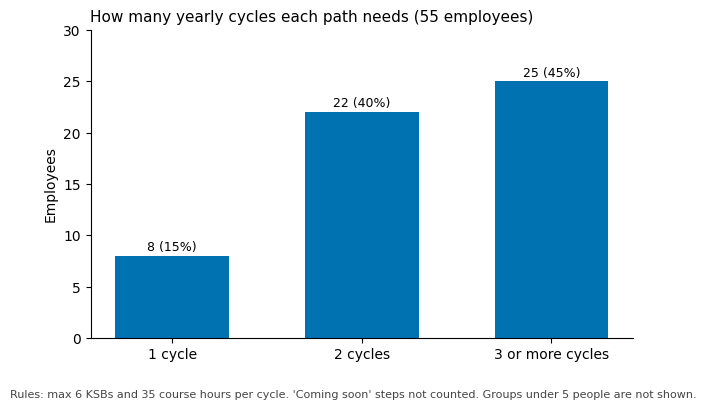

Step 4.3.4.2 executed: fig_4_3_cycles_needed.png saved to reports/figures


In [5]:
# Step 4.3.4: Chart: employees by number of cycles needed (aggregate only, small groups protected)
# Reads (in memory): cycles_needed (from Step 4.3.3)
# Saves: reports/figures/fig_4_3_cycles_needed.png

# Step 4.3.4.1: Group long paths as "3 or more" (top band), then apply the minimum group size check
cycle_band = cycles_needed.astype(int).clip(upper=3).map({1: '1 cycle', 2: '2 cycles', 3: '3 or more cycles'})
band_table = (cycle_band.value_counts().reindex(['1 cycle', '2 cycles', '3 or more cycles'], fill_value=0)
              .rename_axis('cycles').reset_index(name='employees'))
band_table['n'] = band_table['employees']
safe_bands, n_hidden = suppress_small_groups(band_table, 'cycles', 'n')
print(f"Step 4.3.4.1 executed: groups suppressed = {n_hidden}")
print(safe_bands[['cycles', 'employees']].to_string(index=False))

# Step 4.3.4.2: Draw only the groups that passed the check
shown = safe_bands[safe_bands['n'] != f"Suppressed (<{MIN_GROUP_SIZE})"]
n_emps = int(band_table['employees'].sum())

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(shown['cycles'], shown['employees'].astype(int), color=COLORS['knowledge'], width=0.6)
for b, v in zip(bars, shown['employees'].astype(int)):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v} ({v / n_emps:.0%})", ha='center', fontsize=9)
ax.set_ylabel('Employees')
ax.set_ylim(0, shown['employees'].astype(int).max() * 1.2)
ax.set_title(f"How many yearly cycles each path needs ({n_emps} employees)", loc='left', fontsize=11)
fig.text(0.01, -0.04, f"Rules: max {KSB_PER_CYCLE} KSBs and {PATH_HOURS_PER_CYCLE} course hours per cycle. "
         f"'Coming soon' steps not counted. Groups under {MIN_GROUP_SIZE} people are not shown.",
         fontsize=8, color='#444444')

fig_path = os.path.join(FIGURES_DIR, 'fig_4_3_cycles_needed.png')
fig.savefig(fig_path, dpi=FIG_DPI, bbox_inches='tight')
plt.show()
print("Step 4.3.4.2 executed: fig_4_3_cycles_needed.png saved to reports/figures")

### __Step 4.3.4 Notes/Insights__

- A bar chart shows how many employees need 1, 2, or 3 or more yearly cycles. Totals only.
- Paths needing 3 or more cycles are grouped together, so no group is smaller than 5 people.
- All 3 groups passed the privacy check (8, 22 and 25 people). Nothing was hidden.

#### __In real life__

- Paths are revisited every year. After each annual assessment, gaps are recalculated and a fresh path is built.
- Only Year 1 is a real plan. Years 2 and 3 show the size of the need, not a fixed schedule.
- A 3-year upskilling plan does not work in a fast-changing field. By then, the skills and tools may be out of date.
- So L&D puts role-critical and KPI-linked skills first. Small gaps in low-priority skills may be accepted.
- Fast-changing skills (like GenAI tools) need short, often-refreshed content.
- Next step (NB05): prioritise what matters most, so Year 1 covers it.

### __Step 4.3.5: Breakdown by role and office__

- Real dashboards show results by role and location. This is where small groups appear.
- Shows the average yearly cycles and course hours per group.
- Every group goes through the minimum group size check first. Groups under 5 people show "Suppressed (<5)".
  - *Under the hood:* `suppress_small_groups()` from Step 4.1.5 runs on both tables before printing
- Display only. Nothing is saved.

In [6]:
# Step 4.3.5: Breakdown by role and office (aggregate only, small groups suppressed)
# Reads (in memory): phased, cycles_needed, employees, roles

# Step 4.3.5.1: One row per employee with role, office, cycles needed and course hours
assert 'office_id' in employees.columns, f"Expected an office_id column, found: {employees.columns.tolist()}"
per_emp = (pd.DataFrame({'cycles_needed': cycles_needed.astype(int),
                         'course_hours': phased.groupby('employee_id')['duration_minutes'].sum() / 60})
           .rename_axis('employee_id').reset_index()
           .merge(employees[['employee_id', 'role_id', 'office_id']], on='employee_id', how='left')
           .merge(roles[['role_id', 'role_name']], on='role_id', how='left'))

def group_summary(by):
    return (per_emp.groupby(by)
            .agg(n=('employee_id', 'size'),
                 avg_cycles=('cycles_needed', 'mean'),
                 avg_course_hours=('course_hours', 'mean'))
            .round(1).reset_index())

# Step 4.3.5.2: Apply the minimum group size check before showing anything
safe_role, hidden_role = suppress_small_groups(group_summary('role_name'), 'role_name', 'n')
safe_role_office, hidden_ro = suppress_small_groups(group_summary(['role_name', 'office_id']),
                                                    ['role_name', 'office_id'], 'n')

print(f"Step 4.3.5 executed: by role ({hidden_role} group(s) suppressed)")
print(safe_role.to_string(index=False))
print()
print(f"By role and office ({hidden_ro} group(s) suppressed)")
print(safe_role_office.to_string(index=False))

Step 4.3.5 executed: by role (0 group(s) suppressed)
                                role_name  n avg_cycles avg_course_hours
Capability Development/Solution Architect  5        1.8              4.8
                Instructional Design Lead 50        2.4              6.8

By role and office (3 group(s) suppressed)
                                role_name office_id               n      avg_cycles avg_course_hours
Capability Development/Solution Architect    OFF001 Suppressed (<5) Suppressed (<5)  Suppressed (<5)
Capability Development/Solution Architect    OFF002 Suppressed (<5) Suppressed (<5)  Suppressed (<5)
Capability Development/Solution Architect    OFF003 Suppressed (<5) Suppressed (<5)  Suppressed (<5)
                Instructional Design Lead    OFF001              50             2.4              6.8


### __Step 4.3.5 Notes/Insights__

- By role, both groups are shown: 50 Instructional Design Leads and 5 Solution Architects.
- Solution Architects need fewer cycles on average (1.8 vs 2.4) and less course time (4.8 vs 6.8 hours).
- By role and office, the 3 Solution Architect groups (1, 2 and 2 people) are hidden. Their averages could point to a named person.
- The Solution Architect total (5) is shown, but the office split is not. So no one's numbers can be worked out.
- Solution Architects pass only because the limit is 5. Many HR teams use 10, which would hide them at role level too.

### __Step 4.4: Two contrasting paths__

- We show two real paths side by side: one Instructional Design Lead, one Solution Architect.
- Each bar is one step. Colour shows Knowledge, Skill or Behavior. Length shows course minutes.
- A dashed line marks where the next yearly cycle starts.
- The hatched bar is a "coming soon" step (KSB018, no course yet).
- Demo employees are picked by a rule: the person closest to their role's typical (median) path length.


Step 4.4.1 executed: path steps enriched (in memory only)

Step 4.4.2 executed: demo employees selected (median rule)
ID Lead: EMP0476 (role median 12 steps, has a 'coming soon' step)
Solution Architect: EMP0188 (role median 8 steps)



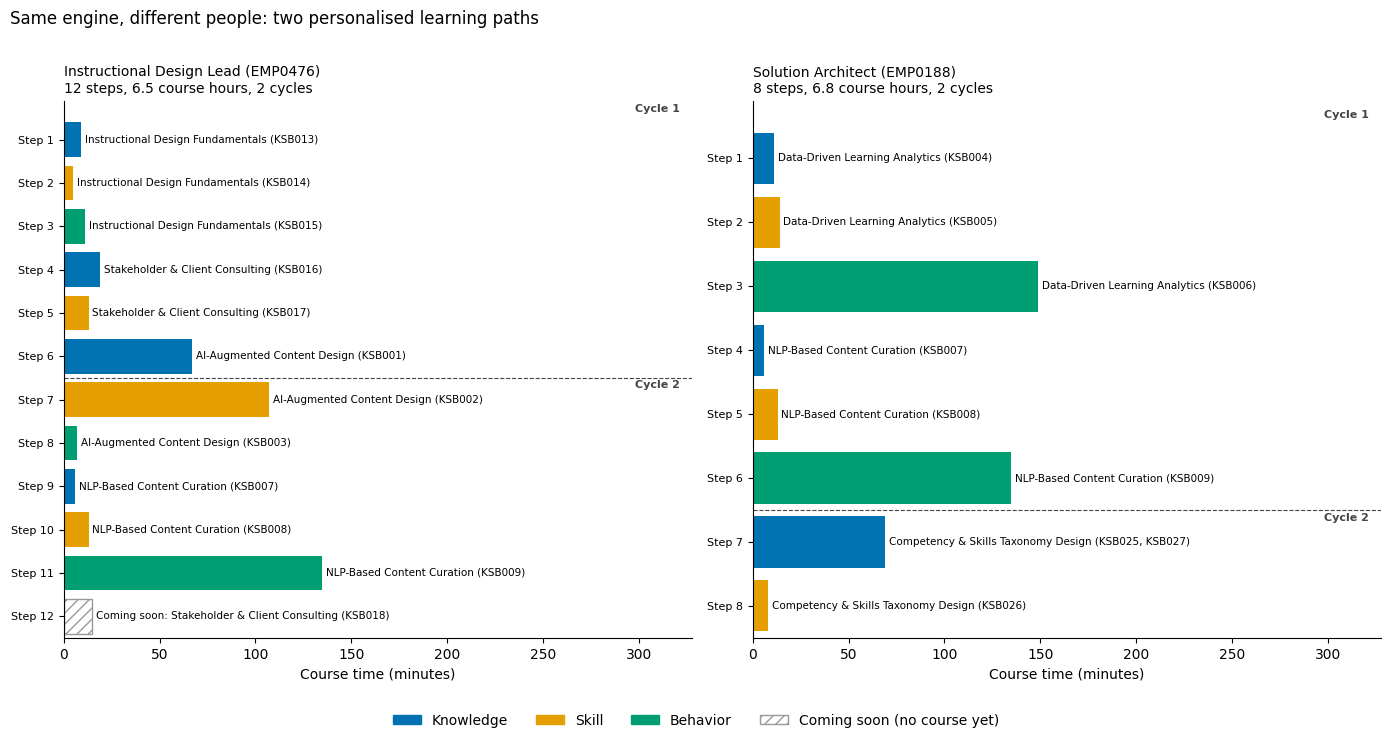

Step 4.4.4 executed: fig_4_4_paths_idlead_vs_sa.png saved to reports/figures

Step 4.4.5: privacy check
Access denied: EMP0476 can only view their own learning path.


In [7]:
# Step 4.4: Two contrasting paths (ID Lead vs Solution Architect)
# Reads (in memory): phased, learning_path_recommendations, employee_ksb_gaps, ksbs, competencies, employees, roles
# Saves: reports/figures/fig_4_4_paths_idlead_vs_sa.png

from matplotlib.patches import Patch

# Step 4.4.1: Add role, KSB type and competency to each path step
KSB_TYPE_ORDER = {'knowledge': 1, 'skill': 2, 'behavior': 3}
step_ksbs = (learning_path_recommendations[['employee_id', 'sequence_order', 'gap_id']]
             .merge(employee_ksb_gaps[['gap_id', 'ksb_id']], on='gap_id', how='left')
             .merge(ksbs[['ksb_id', 'competency_id', 'ksb_type']], on='ksb_id', how='left')
             .merge(competencies, on='competency_id', how='left'))
step_ksbs['type_order'] = step_ksbs['ksb_type'].map(KSB_TYPE_ORDER)
step_info = (step_ksbs.sort_values('type_order')
             .groupby(['employee_id', 'sequence_order'])
             .agg(ksb_ids=('ksb_id', lambda s: ', '.join(sorted(s))), ksb_type=('ksb_type', 'first'),
                  competency_name=('competency_name', 'first'))
             .reset_index())
path_view = (phased.merge(step_info, on=['employee_id', 'sequence_order'], how='left')
             .merge(employees[['employee_id', 'role_id']], on='employee_id', how='left')
             .merge(roles[['role_id', 'role_name']], on='role_id', how='left'))

print("Step 4.4.1 executed: path steps enriched (in memory only)")
print()

# Step 4.4.2: Pick the two demo employees (illustration only; in real life nobody is picked)
steps_per_emp = path_view.groupby(['employee_id', 'role_name'])['sequence_order'].max().reset_index(name='n_steps')
has_gap = path_view.groupby('employee_id')['is_content_gap'].any().rename('has_content_gap')
steps_per_emp = steps_per_emp.merge(has_gap, on='employee_id')

def pick_typical(role_name, need_content_gap=False):
    pool = steps_per_emp[steps_per_emp['role_name'] == role_name].copy()
    median_steps = pool['n_steps'].median()
    if need_content_gap:
        pool = pool[pool['has_content_gap']]
    pool['distance'] = (pool['n_steps'] - median_steps).abs()
    pick = pool.sort_values(['distance', 'employee_id']).iloc[0]
    return pick['employee_id'], median_steps

ID_LEAD = 'Instructional Design Lead'
SOL_ARCH = 'Capability Development/Solution Architect'
demo_idlead, med_idlead = pick_typical(ID_LEAD, need_content_gap=True)
demo_sa, med_sa = pick_typical(SOL_ARCH)

print("Step 4.4.2 executed: demo employees selected (median rule)")
print(f"ID Lead: {demo_idlead} (role median {med_idlead:.0f} steps, has a 'coming soon' step)")
print(f"Solution Architect: {demo_sa} (role median {med_sa:.0f} steps)")
print()

# Step 4.4.3: Privacy gate (same rule as NB03 view_my_path) and the path chart
def can_view(logged_in_id, requested_id):
    """Same rule as NB03 Step 3.5: an employee can only see their own path."""
    if logged_in_id != requested_id:
        print(f"Access denied: {logged_in_id} can only view their own learning path.")
        return False
    return True

COMING_SOON_WIDTH = 15   # minutes; placeholder bar length, the step has no course yet

def plot_path(logged_in_id, requested_id, ax, x_max):
    if not can_view(logged_in_id, requested_id):
        ax.axis('off')
        return
    p = path_view[path_view['employee_id'] == requested_id].sort_values('sequence_order').reset_index(drop=True)
    ax.set_xlim(0, x_max)
    for i, r in p.iterrows():
        if r.is_content_gap:
            width = COMING_SOON_WIDTH
            ax.barh(i, width, color='white', edgecolor=COLORS['content_gap'], hatch='///')
            label = f"Coming soon: {r.competency_name} ({r.ksb_ids})"
        else:
            width = r.duration_minutes
            ax.barh(i, width, color=COLORS[r.ksb_type])
            label = f"{r.competency_name} ({r.ksb_ids})"
        ax.text(width + 2, i, label, va='center', fontsize=7.5)
    # Cycle labels on the right; dashed line where a new cycle starts
    ax.text(x_max * 0.98, -0.6, "Cycle 1", fontsize=8, ha='right', va='bottom', color='#444444', fontweight='bold')
    cyc = p['cycle']
    for i in range(1, len(p)):
        if pd.notna(cyc[i]) and pd.notna(cyc[i - 1]) and cyc[i] != cyc[i - 1]:
            ax.axhline(i - 0.5, color='#444444', ls='--', lw=0.8)
            ax.text(x_max * 0.98, i - 0.45, f"Cycle {cyc[i]}", fontsize=8, ha='right', va='top',
                    color='#444444', fontweight='bold')
    ax.set_yticks(range(len(p)))
    ax.set_yticklabels([f"Step {s}" for s in p['sequence_order']], fontsize=8)
    ax.set_ylim(len(p) - 0.5, -0.9)
    ax.set_xlabel('Course time (minutes)')
    hours = p['duration_minutes'].sum() / 60
    n_cycles = int(p['cycle'].max())
    role_short = 'Instructional Design Lead' if p['role_name'].iloc[0] == ID_LEAD else 'Solution Architect'
    ax.set_title(f"{role_short} ({requested_id})\n{len(p)} steps, {hours:.1f} course hours, {n_cycles} cycles",
                 loc='left', fontsize=10)

# Step 4.4.4: Draw both paths side by side; each demo employee "logs in" as themselves
demo_ids = [demo_idlead, demo_sa]
max_steps = steps_per_emp.loc[steps_per_emp['employee_id'].isin(demo_ids), 'n_steps'].max()
x_max = path_view.loc[path_view['employee_id'].isin(demo_ids), 'duration_minutes'].max() * 2.2   # same scale, room for labels
fig, axes = plt.subplots(1, 2, figsize=(14, 0.4 * max_steps + 2.5))
plot_path(demo_idlead, demo_idlead, axes[0], x_max)
plot_path(demo_sa, demo_sa, axes[1], x_max)

legend = [Patch(color=COLORS['knowledge'], label='Knowledge'), Patch(color=COLORS['skill'], label='Skill'),
          Patch(color=COLORS['behavior'], label='Behavior'),
          Patch(facecolor='white', edgecolor=COLORS['content_gap'], hatch='///', label='Coming soon (no course yet)')]
fig.legend(handles=legend, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Same engine, different people: two personalised learning paths', x=0.01, ha='left', fontsize=12)
fig.tight_layout(rect=(0, 0.04, 1, 0.97))

fig_path = os.path.join(FIGURES_DIR, 'fig_4_4_paths_idlead_vs_sa.png')
fig.savefig(fig_path, dpi=FIG_DPI, bbox_inches='tight')
plt.show()
print("Step 4.4.4 executed: fig_4_4_paths_idlead_vs_sa.png saved to reports/figures")
print()

# Step 4.4.5: Privacy check: one employee tries to chart a colleague's path
print("Step 4.4.5: privacy check")
fig_test, ax_test = plt.subplots(figsize=(3, 1))
plot_path(demo_idlead, demo_sa, ax_test, x_max)
plt.close(fig_test)

### __Step 4.4 Notes/Insights__

- Same engine, different paths. The ID Lead (EMP0476) starts with Instructional Design Fundamentals and Stakeholder Consulting.
- The Solution Architect (EMP0188) starts with Data-Driven Learning Analytics.
- Both share one need, NLP-Based Content Curation. The overlap is small, as the role profiles intend.
- Every competency follows Knowledge, then Skill, then Behavior (blue, orange, green).
- The Solution Architect's Step 7 is one shared course covering two KSBs (KSB025, KSB027), so it is shown once.
- The ID Lead's last step is "coming soon" (KSB018). The need is visible, not hidden.
- Both paths need 2 cycles because of the 6-KSB cap, even though each is under 7 course hours.
- Path charts use the same privacy check as NB03: an employee can only see their own path.
  - *Under the hood:* `plot_path()` calls `can_view(logged_in_id, requested_id)` and draws nothing if the IDs differ
  - Employees see their path on Workday (or a similar platform), signed in through Single Sign-On.
  - **Under the hood: SSO confirms who is logged in, so `logged_in_id` comes from the company login, not from code.**
- Saved as `fig_4_4_paths_idlead_vs_sa.png`. Employee IDs only, no names.

### __Step 4.5: KPI dashboard (aggregate only)__

- Shows leaders where we are, where paths could take us, and where we must be.
- K2.2: KSBs closed per employee per year. Target 6.
- K2.1: % of focus-role employees meeting all 3 core DS/ML/GenAI competencies. Target 60%.
- Dark bar: actual. Light bars: projections (conservative and optimistic). Dashed line: target.
- Totals only, no individual data.
  - *Under the hood:* values are read from `outputs/kpi_impact_rollup.csv` (NB03 Step 3.6), not typed in
- Saved as `fig_4_5_kpi_dashboard.png`.

Step 4.5.1 executed: KPI values read from kpi_impact_rollup.csv
K2.2 (KSBs closed per employee per year): now 3.2, projected 9.6 to 12.1, target 6
K2.1 (% meeting all 3 core competencies): now 9.1%, projected 70.9% to 100.0%, target 60%

Step 4.5.1a: KPI population 55 passes the minimum group size of 5


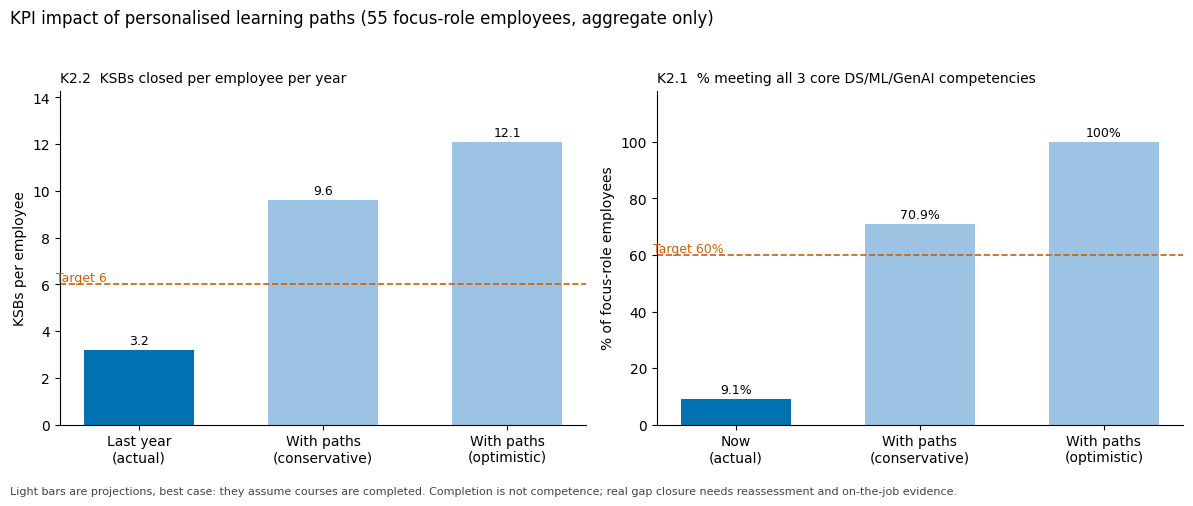

Step 4.5.2 executed: fig_4_5_kpi_dashboard.png saved to reports/figures


In [8]:
# Step 4.5: KPI dashboard (aggregate only)
# Reads (in memory): kpi_impact_rollup
# Saves: reports/figures/fig_4_5_kpi_dashboard.png

# Step 4.5.1: Pull actual, conservative and optimistic values and the target for each KPI
def kpi_values(kpi_id):
    rows = kpi_impact_rollup[kpi_impact_rollup['kpi_id'] == kpi_id]
    metric = rows['metric'].str.lower()
    pick = lambda word: rows.loc[metric.str.contains(word), 'value'].iloc[0]
    now = pick('actual') if kpi_id == 'K2.2' else pick('now')
    target = float(str(rows['target'].iloc[0]).split()[0].rstrip('%'))   # '6 KSBs/year' -> 6, '60%' -> 60
    return [now, pick('conservative'), pick('optimistic')], target

k22_vals, k22_target = kpi_values('K2.2')
k21_vals, k21_target = kpi_values('K2.1')

print("Step 4.5.1 executed: KPI values read from kpi_impact_rollup.csv")
print(f"K2.2 (KSBs closed per employee per year): now {k22_vals[0]}, projected {k22_vals[1]} to {k22_vals[2]}, target {k22_target:g}")
print(f"K2.1 (% meeting all 3 core competencies): now {k21_vals[0]}%, projected {k21_vals[1]}% to {k21_vals[2]}%, target {k21_target:g}%")
print()

# Step 4.5.1a: Minimum group size check on the KPI population (55 focus-role employees) (14 Oct 2026)
kpi_population = pd.DataFrame({'group': ['All focus-role employees'],
                               'n': [path_view['employee_id'].nunique()]})
_, kpi_hidden = suppress_small_groups(kpi_population, 'group', 'n')
assert kpi_hidden == 0, "KPI population is below MIN_GROUP_SIZE; do not show the dashboard"
print(f"Step 4.5.1a: KPI population {kpi_population['n'].iloc[0]} passes the minimum group size of {MIN_GROUP_SIZE}")


# Step 4.5.2: Two-panel dashboard; projections in a lighter shade, target as a dashed line
PROJECTED_SHADE = '#9CC3E4'
projected_labels = ['With paths\n(conservative)', 'With paths\n(optimistic)']
bar_colors = [COLORS['knowledge'], PROJECTED_SHADE, PROJECTED_SHADE]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
panels = [
    (axes[0], k22_vals, k22_target, 'K2.2  KSBs closed per employee per year', '', 'KSBs per employee',
     'Last year\n(actual)'),
    (axes[1], k21_vals, k21_target, 'K2.1  % meeting all 3 core DS/ML/GenAI competencies', '%',
     '% of focus-role employees', 'Now\n(actual)'),
]
for ax, vals, target, title, unit, ylabel, actual_label in panels:
    bars = ax.bar([actual_label] + projected_labels, vals, color=bar_colors, width=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + max(vals) * 0.02, f"{v:g}{unit}", ha='center', fontsize=9)
    ax.axhline(target, color=COLORS['target'], ls='--', lw=1.2)
    ax.text(-0.45, target, f"Target {target:g}{unit}", color=COLORS['target'], fontsize=9, ha='left', va='bottom')
    ax.set_ylim(0, max(max(vals), target) * 1.18)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc='left', fontsize=10)

fig.suptitle('KPI impact of personalised learning paths (55 focus-role employees, aggregate only)',
             x=0.01, ha='left', fontsize=12)
fig.text(0.01, -0.03, "Light bars are projections, best case: they assume courses are completed. "
         "Completion is not competence; real gap closure needs reassessment and on-the-job evidence.",
         fontsize=8, color='#444444')
fig.tight_layout(rect=(0, 0, 1, 0.95))

fig_path = os.path.join(FIGURES_DIR, 'fig_4_5_kpi_dashboard.png')
fig.savefig(fig_path, dpi=FIG_DPI, bbox_inches='tight')
plt.show()
print("Step 4.5.2 executed: fig_4_5_kpi_dashboard.png saved to reports/figures")

### __Step 4.5 Notes/Insights__

- **Skills learned per year (K2.2):** last year, each person built about 3 new skills. The goal is 6.
- With learning paths, each person could build 10 to 12 skills. That is too much for one year, so paths are spread over 2 or more years (Step 4.3).
- **Core AI skills (K2.1):** today, only about 1 in 10 people have all 3 core AI skills. The goal is 6 in 10.
- With learning paths, 7 to 10 in every 10 people could get there.
- These are best-case numbers. They assume people finish their courses.
- Finishing a course does not prove someone can do the job. That needs a new assessment, manager feedback and real work practice.
- **Privacy check:** the dashboard covers 55 people, above the minimum group size of 5, so it is safe to show.

### __Step 4.6: Figure index__

- Lists every figure NB04 saved, for use in the README.
- Checks that each file exists in `reports/figures/`.

In [9]:
# Step 4.6: Figure index for the README
# Reads: reports/figures/*.png

# Step 4.6.1: Expected figures and what each one shows
FIGURE_INDEX = [
    ('fig_4_2_curation_flow.png', 'Step 4.2', 'Where L&D judgment sits: 30 AI matches to approved courses'),
    ('fig_4_3_cycles_needed.png', 'Step 4.3', 'How many yearly cycles each path needs (aggregate)'),
    ('fig_4_4_paths_idlead_vs_sa.png', 'Step 4.4', 'Two contrasting paths: ID Lead vs Solution Architect'),
    ('fig_4_5_kpi_dashboard.png', 'Step 4.5', 'KPI impact: K2.2 and K2.1, actual vs projected vs target'),
]

# Step 4.6.2: Check each file exists and show its size
index = pd.DataFrame(FIGURE_INDEX, columns=['file', 'notebook_step', 'shows'])
index['exists'] = index['file'].apply(lambda f: os.path.exists(os.path.join(FIGURES_DIR, f)))
index['size_kb'] = index.apply(
    lambda r: round(os.path.getsize(os.path.join(FIGURES_DIR, r.file)) / 1024) if r.exists else None, axis=1)

assert index['exists'].all(), f"Missing figures: {index.loc[~index['exists'], 'file'].tolist()}"

print("Step 4.6 executed: all figures found in reports/figures")
print(index.to_string(index=False))

Step 4.6 executed: all figures found in reports/figures
                          file notebook_step                                                      shows  exists  size_kb
     fig_4_2_curation_flow.png      Step 4.2 Where L&D judgment sits: 30 AI matches to approved courses    True       98
     fig_4_3_cycles_needed.png      Step 4.3         How many yearly cycles each path needs (aggregate)    True       47
fig_4_4_paths_idlead_vs_sa.png      Step 4.4       Two contrasting paths: ID Lead vs Solution Architect    True      219
     fig_4_5_kpi_dashboard.png      Step 4.5   KPI impact: K2.2 and K2.1, actual vs projected vs target    True       97


### __Step 4.6 Notes__

- All 4 figures are saved in `reports/figures/` and ready for the README.
- Each file name starts with its step number, so a reader can trace any picture back to the code that made it.
- Files are small (42 to 219 KB), so they load quickly on GitHub.

### __NB04 Summary__

**What NB04 showed:**
- **Human review:** AI handled 11 of 30 course matches. L&D decided the other 19 and found 1 skill with no suitable course (KSB018).
- **Phasing:** with 35 learning hours and 6 skills a year, only 8 of 55 people can finish their path in one year. Most need 2 or 3 years. That is too long for fast-changing skills, so paths are revisited every year. The next part of the demo (coming soon) will prioritise what matters most.
- **Personalisation:** an ID Lead and a Solution Architect get very different paths from the same engine.
- **Privacy:** employees see only their own path. Leaders see totals only, and groups under 5 people are never shown.
- **Business impact:** paths could double skill-building and lift core AI skills from 1 in 10 people to 7 in 10 or more. Best case only.

**Phase 1 is complete:**
- Data, gaps, matching, human review, paths, privacy and KPI impact are all built.

**Coming next:**
- Phase 2: coming soon
- Phase 3: coming soon

### __End of NB04__